# 06 · Step 6: Offer types: reminder vs discount vs reward (gate K6)
**Question:** which offer type creates the most value *after its cost*, and does the best offer depend on the customer?

| Part | Data | What we do |
|---|---|---|
| A | **Starbucks** (simulated by Starbucks for Udacity): 17,000 customers, 6 offer waves, 10 offers of 3 types | Turn every customer-wave into an experiment row, check it is random, measure lift, spend and **net value after the reward paid**, then compare across customer groups |
| B | **Hillstrom** (real, 2008 US e-commerce): 64,000 customers, men's email vs women's email vs no email | Check it is random, measure lift in visits, purchases and spend, find who responds to which email |

**Offer ladder:** informational = reminder (free) · discount = money off when you spend enough · buy-one-get-one (BOGO) = a reward, the most generous.

## Cell 0 · Setup

In [1]:
import pandas as pd, numpy as np, duckdb, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from pathlib import Path
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
RAW = Path('..') / 'data_offers' / 'raw'; CLEAN = Path('..') / 'data_offers' / 'clean'; CLEAN.mkdir(exist_ok=True)

def lift_ci(a, b):
    '''difference in means a - b, with a 95% range'''
    d = a.mean() - b.mean(); se = np.sqrt(a.var() / len(a) + b.var() / len(b))
    return d, d - 1.96 * se, d + 1.96 * se
def std_diff(a, b):
    a, b = a.dropna(), b.dropna(); return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
print('ready')

ready


## Part A · Starbucks
### Cell A0 · Load the three files
- **portfolio:** the 10 offers (type, spend needed = difficulty, reward, days valid, channels)
- **profile:** 17,000 customers (age, gender, income, membership date). Age 118 = missing demographics.
- **transcript:** 306,534 events: offer received / viewed / completed, and every purchase with its amount. Time is in hours from the start.

In [2]:
pf = pd.read_json(RAW / 'starbucks_portfolio.json.gz', lines=True, compression='gzip')
pr = pd.read_json(RAW / 'starbucks_profile.json.gz', lines=True, compression='gzip')
tr = pd.read_json(RAW / 'starbucks_transcript.json.gz', lines=True, compression='gzip')
tr['offer_id'] = tr.value.apply(lambda v: v.get('offer id', v.get('offer_id')))
tr['amount'] = tr.value.apply(lambda v: v.get('amount'))
tr['reward'] = tr.value.apply(lambda v: v.get('reward'))
pf['offer_name'] = pf.offer_type.str.upper().str[:4] + ' ' + pf.difficulty.astype(str) + '/' + pf.reward.astype(str) + ' ' + pf.duration.astype(int).astype(str) + 'd'
display(pf[['offer_name', 'offer_type', 'difficulty', 'reward', 'duration', 'channels']])
print(pr.shape, tr.shape); print(tr.event.value_counts())

,offer_name,offer_type,difficulty,reward,duration,channels
0,BOGO 10/10 7d,bogo,10,10,7,"[email, mobile, social]"
1,BOGO 10/10 5d,bogo,10,10,5,"[web, email, mobile, social]"
2,INFO 0/0 4d,informational,0,0,4,"[web, email, mobile]"
3,BOGO 5/5 7d,bogo,5,5,7,"[web, email, mobile]"
4,DISC 20/5 10d,discount,20,5,10,"[web, email]"
5,DISC 7/3 7d,discount,7,3,7,"[web, email, mobile, social]"
6,DISC 10/2 10d,discount,10,2,10,"[web, email, mobile, social]"
7,INFO 0/0 3d,informational,0,0,3,"[email, mobile, social]"
8,BOGO 5/5 5d,bogo,5,5,5,"[web, email, mobile, social]"
9,DISC 10/2 7d,discount,10,2,7,"[web, email, mobile]"


(17000, 5) (306534, 7)
event
transaction        138953
offer received      76277
offer viewed        57725
offer completed     33579
Name: count, dtype: int64


### Cell A1 · Build the experiment table (one row per customer per wave)
Offers go out at 6 moments (hours 0, 168, 336, 408, 504, 576). For each customer and wave: which offer (or none), then in the **next 72 hours**: did they buy, how much did they spend, how much reward did Starbucks pay for *that* offer. 72 hours is the shortest gap between waves, so windows never overlap.

In [3]:
WAVES, WIN = [0, 168, 336, 408, 504, 576], 72
grid = pd.MultiIndex.from_product([pr.id, WAVES], names=['person', 'time']).to_frame(index=False)
rec = tr[tr.event == 'offer received'][['person', 'time', 'offer_id']]
x = grid.merge(rec, on=['person', 'time'], how='left').merge(pf[['id', 'offer_type', 'offer_name', 'difficulty', 'reward']].rename(columns={'id': 'offer_id'}), on='offer_id', how='left')
x['offer_type'] = x.offer_type.fillna('none'); x[['difficulty', 'reward']] = x[['difficulty', 'reward']].fillna(0)

tx = tr[tr.event == 'transaction'][['person', 'time', 'amount']].rename(columns={'time': 't_tx'})
m = x[['person', 'time']].merge(tx, on='person'); m = m[(m.t_tx >= m.time) & (m.t_tx < m.time + WIN)]
x = x.merge(m.groupby(['person', 'time']).amount.agg(spend='sum', n_tx='size').reset_index(), on=['person', 'time'], how='left')
comp = tr[tr.event == 'offer completed'][['person', 'time', 'offer_id', 'reward']].rename(columns={'time': 't_c', 'reward': 'paid'})
mc = x[['person', 'time', 'offer_id']].dropna().merge(comp, on=['person', 'offer_id']); mc = mc[(mc.t_c >= mc.time) & (mc.t_c < mc.time + WIN)]
x = x.merge(mc.groupby(['person', 'time']).paid.sum().reset_index(), on=['person', 'time'], how='left')
x[['spend', 'n_tx', 'paid']] = x[['spend', 'n_tx', 'paid']].fillna(0)
x['bought'] = (x.n_tx > 0).astype(int); x['net'] = x.spend - x.paid

p = pr.rename(columns={'id': 'person'}).copy()
p['missing_demo'] = (p.age == 118).astype(int); p.loc[p.age == 118, 'age'] = np.nan
p['member_days'] = (pd.Timestamp('2018-07-27') - pd.to_datetime(p.became_member_on.astype(str))).dt.days
p['female'] = (p.gender == 'F').astype(float).where(p.gender.notna())
x = x.merge(p[['person', 'age', 'income', 'member_days', 'female', 'missing_demo']], on='person')
duckdb.register('x_df', x.drop(columns=['offer_id']))
duckdb.sql(f"COPY x_df TO '{(CLEAN / 'starbucks_waves.parquet').as_posix()}' (FORMAT PARQUET)")
print(f'{len(x):,} customer-waves'); display(x.offer_type.value_counts(normalize=True).round(3))

102,000 customer-waves


offer_type
discount         0.299
bogo             0.299
none             0.252
informational    0.149
Name: proportion, dtype: float64

### Cell A2 · K6 check: is the offer random?
Every offer group is compared with the no-offer group on things fixed *before* the offer. Under 0.05 = same.

In [4]:
ctrl = x[x.offer_type == 'none']
bal = pd.DataFrame({ot: {c: std_diff(x[x.offer_type == ot][c], ctrl[c]) for c in ['age', 'income', 'member_days', 'female', 'missing_demo']}
                    for ot in ['informational', 'discount', 'bogo']}).round(4)
display(bal); print('largest |std diff|:', bal.abs().max().max())

,informational,discount,bogo
age,0.0054,-0.0089,-0.0077
income,-0.0061,-0.0086,-0.0037
member_days,0.0005,-0.0086,-0.0016
female,0.0027,-0.0095,-0.0030
missing_demo,-0.0008,-0.0008,0.0078


largest |std diff|: 0.0095


### Cell A3 · What each offer type does (vs no offer)
- **Buy lift:** extra share of customers who buy within 72 hours.
- **Spend lift:** extra spend per customer.
- **Reward paid:** average reward Starbucks paid per customer who got the offer.
- **Net value:** spend lift minus reward paid. This is what the business keeps (before product margin).

,buy_lift_pts,buy_low95,buy_high95,spend_lift,reward_paid,net_value,net_low95,net_high95
offer_type,,,,,,,,
informational,12.47,11.47,13.46,3.71,0.00,3.71,3.13,4.28
discount,13.82,13.00,14.64,5.04,0.90,4.13,3.63,4.64
bogo,17.17,16.36,17.99,5.82,2.68,3.14,2.62,3.65


no-offer baseline: 42.9% buy within 72h, average spend 7.58


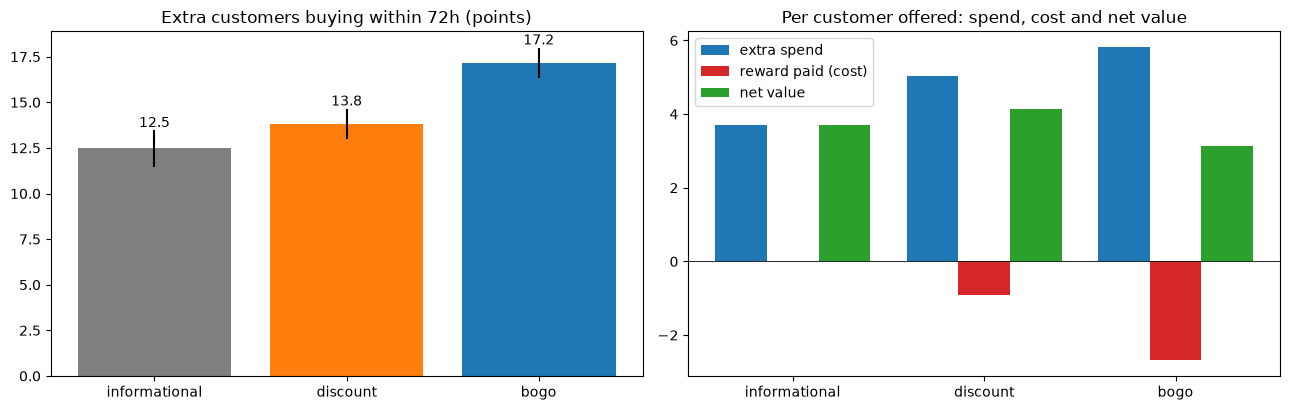

In [5]:
rows = []
for ot in ['informational', 'discount', 'bogo']:
    g = x[x.offer_type == ot]
    b = lift_ci(g.bought, ctrl.bought); s = lift_ci(g.spend, ctrl.spend); n = lift_ci(g.net, ctrl.net)
    rows.append({'offer_type': ot, 'buy_lift_pts': 100 * b[0], 'buy_low95': 100 * b[1], 'buy_high95': 100 * b[2],
                 'spend_lift': s[0], 'reward_paid': g.paid.mean(), 'net_value': n[0], 'net_low95': n[1], 'net_high95': n[2]})
OT = pd.DataFrame(rows).set_index('offer_type'); display(OT.round(2))
print(f'no-offer baseline: {100 * ctrl.bought.mean():.1f}% buy within 72h, average spend {ctrl.spend.mean():.2f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar(OT.index, OT.buy_lift_pts, yerr=[OT.buy_lift_pts - OT.buy_low95, OT.buy_high95 - OT.buy_lift_pts], color=['tab:gray', 'tab:orange', 'tab:blue'])
ax[0].set_title('Extra customers buying within 72h (points)'); ax[0].bar_label(ax[0].containers[1], fmt='%.1f')
w = 0.27; i = np.arange(3)
ax[1].bar(i - w, OT.spend_lift, w, label='extra spend'); ax[1].bar(i, -OT.reward_paid, w, label='reward paid (cost)', color='tab:red')
ax[1].bar(i + w, OT.net_value, w, label='net value', color='tab:green'); ax[1].axhline(0, c='black', lw=0.6)
ax[1].set_xticks(i); ax[1].set_xticklabels(OT.index); ax[1].legend(); ax[1].set_title('Per customer offered: spend, cost and net value')
plt.tight_layout(); plt.show()

### Cell A4 · All 10 offers, ranked by net value
Name format: TYPE spend-needed / reward / days valid. Channels matter too: offers sent on social media reach more people.

,offer,type,social,buy_lift_pts,spend_lift,reward_paid,net_value
0,DISC 10/2 10d,discount,True,22.07,8.16,0.81,7.35
1,DISC 7/3 7d,discount,True,20.98,7.05,1.34,5.72
2,BOGO 5/5 5d,bogo,True,20.33,7.13,2.21,4.92
3,INFO 0/0 3d,informational,True,16.66,4.68,0.00,4.68
4,BOGO 10/10 5d,bogo,True,21.37,6.72,3.43,3.30
5,BOGO 10/10 7d,bogo,True,18.16,6.11,3.29,2.82
6,INFO 0/0 4d,informational,False,8.28,2.73,0.00,2.73
7,DISC 10/2 7d,discount,False,8.03,3.16,0.62,2.54
8,BOGO 5/5 7d,bogo,False,8.92,3.35,1.82,1.54
9,DISC 20/5 10d,discount,False,4.26,1.80,0.85,0.96


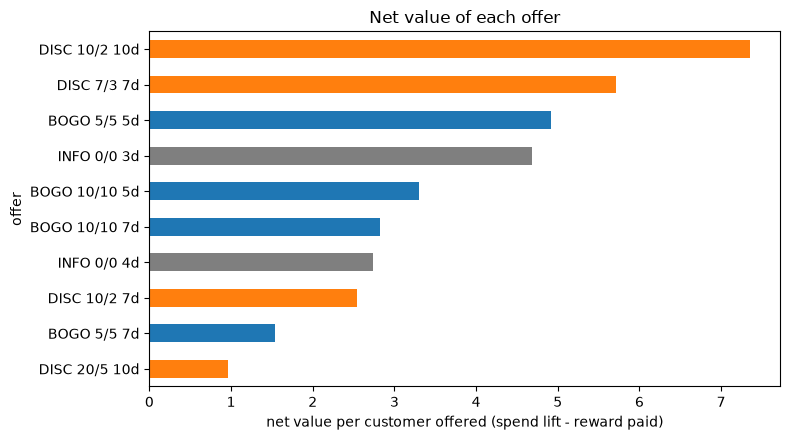

In [6]:
rows = []
for oid, g in x[x.offer_type != 'none'].groupby('offer_name'):
    o = pf.set_index('offer_name').loc[oid]
    rows.append({'offer': oid, 'type': o.offer_type, 'social': 'social' in o.channels, 'buy_lift_pts': 100 * (g.bought.mean() - ctrl.bought.mean()),
                 'spend_lift': g.spend.mean() - ctrl.spend.mean(), 'reward_paid': g.paid.mean(), 'net_value': g.net.mean() - ctrl.net.mean()})
OF = pd.DataFrame(rows).sort_values('net_value', ascending=False).reset_index(drop=True); display(OF.round(2))
ax = OF.set_index('offer').net_value[::-1].plot.barh(figsize=(8, 4.5), color=[{'bogo': 'tab:blue', 'discount': 'tab:orange', 'informational': 'tab:gray'}[t] for t in OF.type[::-1]])
ax.set_xlabel('net value per customer offered (spend lift - reward paid)'); ax.set_title('Net value of each offer'); plt.tight_layout(); plt.show()

### Cell A5 · Does the best offer depend on the customer?
Net value of each offer type, within customer groups. The best cell in each row is the offer to send that group.

,customers_share_%,informational,discount,bogo,best_offer
group,,,,,
income_band: <50k,23.73,2.82,2.59,2.31,informational
income_band: 50-75k,37.86,4.90,4.55,3.47,informational
income_band: 75k+,25.62,4.17,6.62,4.76,discount
age_band: <35,13.96,4.49,3.02,3.27,informational
age_band: 35-55,30.08,4.27,4.46,3.67,discount
age_band: 55+,43.16,3.88,5.24,3.50,discount
tenure_band: <1 yr,51.12,2.25,1.94,1.22,informational
tenure_band: 1-2 yrs,20.37,5.88,7.94,6.32,discount
tenure_band: 2+ yrs,28.51,4.78,5.53,4.39,discount


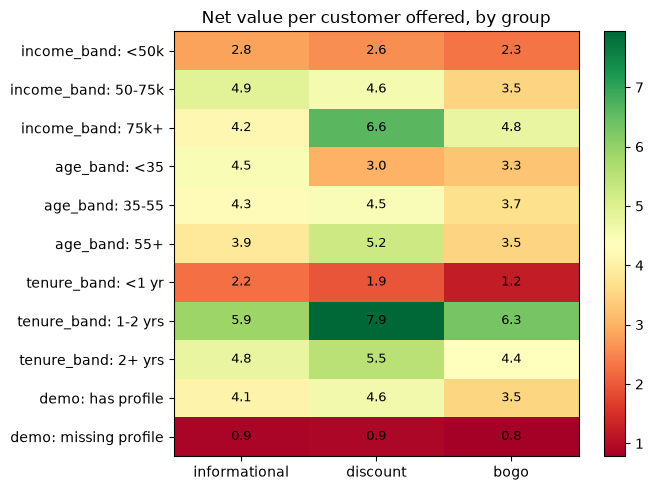

In [7]:
x['income_band'] = pd.cut(x.income, [0, 50000, 75000, 1e9], labels=['<50k', '50-75k', '75k+'])
x['age_band'] = pd.cut(x.age, [0, 35, 55, 120], labels=['<35', '35-55', '55+'])
x['tenure_band'] = pd.cut(x.member_days, [-1, 365, 730, 1e5], labels=['<1 yr', '1-2 yrs', '2+ yrs'])
x['demo'] = np.where(x.missing_demo == 1, 'missing profile', 'has profile')
H = []
for col in ['income_band', 'age_band', 'tenure_band', 'demo']:
    for lvl, g in x.groupby(col, observed=True):
        c = g[g.offer_type == 'none']; row = {'group': f'{col}: {lvl}', 'customers_share_%': 100 * len(g) / len(x)}
        for ot in ['informational', 'discount', 'bogo']:
            row[ot] = g[g.offer_type == ot].net.mean() - c.net.mean()
        row['best_offer'] = max(['informational', 'discount', 'bogo'], key=lambda k: row[k]); H.append(row)
HET = pd.DataFrame(H).set_index('group'); display(HET.round(2))
fig, ax = plt.subplots(figsize=(7, 5)); v = HET[['informational', 'discount', 'bogo']]
im = ax.imshow(v.values, cmap='RdYlGn', aspect='auto'); ax.set_xticks(range(3)); ax.set_xticklabels(v.columns); ax.set_yticks(range(len(v))); ax.set_yticklabels(v.index)
for i in range(v.shape[0]):
    for j in range(3): ax.text(j, i, f'{v.values[i, j]:.1f}', ha='center', va='center', fontsize=9)
ax.set_title('Net value per customer offered, by group'); plt.colorbar(im); plt.tight_layout(); plt.show()

## Part B · Hillstrom (real email experiment)
### Cell B0 · Load and K6 check
64,000 customers who bought in the past year were split at random: one third got a men's merchandise email, one third a women's, one third nothing. Outcomes over the next 2 weeks: visited the site, bought, spend.

In [8]:
h = pd.read_csv(RAW / 'hillstorm_no_indices.csv.gz')
print(h.shape); display(h.head(3)); display(h.segment.value_counts())
h = pd.concat([h, pd.get_dummies(h.zip_code, prefix='area').astype(int), pd.get_dummies(h.channel, prefix='chan').astype(int)], axis=1)
hc = h[h.segment == 'No E-Mail']
pre = ['recency', 'history', 'mens', 'womens', 'newbie'] + [c for c in h.columns if c.startswith(('area_', 'chan_'))]
hbal = pd.DataFrame({s: {c: std_diff(h[h.segment == s][c].astype(float), hc[c].astype(float)) for c in pre} for s in ['Mens E-Mail', 'Womens E-Mail']}).round(4)
display(hbal); print('largest |std diff|:', hbal.abs().max().max())
duckdb.register('h_df', h); duckdb.sql(f"COPY h_df TO '{(CLEAN / 'hillstrom.parquet').as_posix()}' (FORMAT PARQUET)")

(64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0


segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

,Mens E-Mail,Womens E-Mail
recency,0.0068,0.0052
history,0.0076,0.0065
mens,-0.0046,-0.0086
womens,0.0076,0.0049
newbie,-0.0009,0.0026
area_Rural,0.0137,0.0040
area_Surburban,-0.0117,-0.0011
area_Urban,0.0020,-0.0018
chan_Multichannel,-0.0042,-0.0053
chan_Phone,-0.0083,0.0086


largest |std diff|: 0.0137


### Cell B1 · What each email does (vs no email)

In [9]:
rows = []
for s in ['Mens E-Mail', 'Womens E-Mail']:
    g = h[h.segment == s]; r = {'email': s}
    for col, mult in [('visit', 100), ('conversion', 100), ('spend', 1)]:
        d, lo, hi = lift_ci(g[col], hc[col]); r[f'{col}_lift'] = d * mult; r[f'{col}_low95'] = lo * mult; r[f'{col}_high95'] = hi * mult
    rows.append(r)
HE = pd.DataFrame(rows).set_index('email'); display(HE.round(3))
print(f"no-email baseline: visit {100 * hc.visit.mean():.1f}%, buy {100 * hc.conversion.mean():.2f}%, spend {hc.spend.mean():.3f} per customer")

,visit_lift,visit_low95,visit_high95,conversion_lift,conversion_low95,conversion_high95,spend_lift,spend_low95,spend_high95
email,,,,,,,,,
Mens E-Mail,7.659,6.995,8.323,0.681,0.50,0.861,0.770,0.485,1.055
Womens E-Mail,4.523,3.889,5.157,0.311,0.15,0.472,0.424,0.169,0.680


no-email baseline: visit 10.6%, buy 0.57%, spend 0.653 per customer


### Cell B2 · Who responds to which email?
Visit lift (points) of each email within groups. Watch the "past buyer type" rows: does the men's email only work on people who bought men's items before?

,share_%,mens_email_visit_lift,mens_email_spend_lift,womens_email_visit_lift,womens_email_spend_lift,better_email
group,,,,,,
buyer_type: both,10.07,13.44,1.82,7.11,0.16,mens
buyer_type: mens only,45.03,6.92,0.68,1.11,0.28,mens
buyer_type: womens only,44.90,7.06,0.62,7.40,0.63,womens
recency_band: 1-3 months,34.99,8.50,1.05,4.40,0.36,mens
recency_band: 4-6 months,22.18,7.55,0.49,4.05,0.67,womens
recency_band: 7-12 months,42.84,7.04,0.69,4.87,0.35,mens
zip_code: Rural,14.94,7.34,0.76,2.91,0.51,mens
zip_code: Surburban,44.96,7.43,0.80,4.89,0.18,mens
zip_code: Urban,40.10,7.96,0.74,4.69,0.67,mens


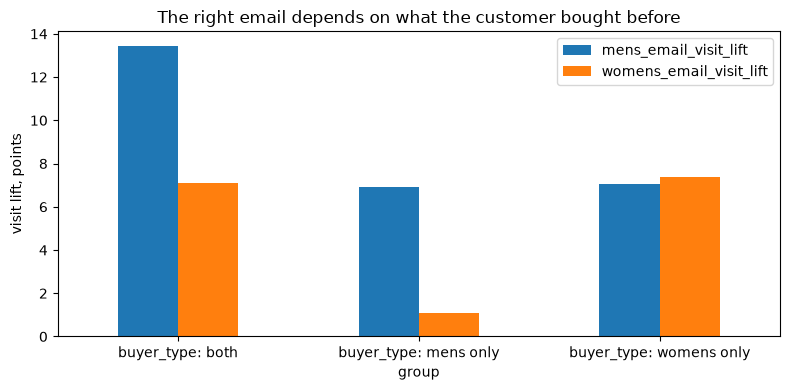

In [10]:
h['buyer_type'] = np.select([(h.mens == 1) & (h.womens == 1), h.mens == 1, h.womens == 1], ['both', 'mens only', 'womens only'], 'neither')
h['recency_band'] = pd.cut(h.recency, [0, 3, 6, 12], labels=['1-3 months', '4-6 months', '7-12 months'])
R = []
for col in ['buyer_type', 'recency_band', 'zip_code', 'channel', 'newbie']:
    for lvl, g in h.groupby(col, observed=True):
        c = g[g.segment == 'No E-Mail']; row = {'group': f'{col}: {lvl}', 'share_%': 100 * len(g) / len(h)}
        for s, k in [('Mens E-Mail', 'mens_email'), ('Womens E-Mail', 'womens_email')]:
            row[f'{k}_visit_lift'] = 100 * (g[g.segment == s].visit.mean() - c.visit.mean())
            row[f'{k}_spend_lift'] = g[g.segment == s].spend.mean() - c.spend.mean()
        row['better_email'] = 'mens' if row['mens_email_spend_lift'] > row['womens_email_spend_lift'] else 'womens'
        R.append(row)
HH = pd.DataFrame(R).set_index('group'); display(HH.round(2))
ax = HH[['mens_email_visit_lift', 'womens_email_visit_lift']].loc[[i for i in HH.index if i.startswith('buyer_type')]].plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel('visit lift, points'); ax.set_title('The right email depends on what the customer bought before'); plt.tight_layout(); plt.show()

## Cell K6 · Verdict

In [11]:
checks = {
  'Starbucks is random (all |std diff| < 0.05)': bal.abs().max().max() < 0.05,
  'Hillstrom is random (all |std diff| < 0.05)': hbal.abs().max().max() < 0.05,
  'At least one offer lifts buying (95% range above 0)': (OT.buy_low95 > 0).any() or (HE.conversion_low95 > 0).any(),
  'Best offer differs between customer groups': HET.best_offer.nunique() > 1 or HH.better_email.nunique() > 1,
}
for k, v in checks.items(): print(f'{"PASS" if v else "FAIL"}  {k}')
print('\nK6 VERDICT:', 'PASS' if all(checks.values()) else 'REVIEW')

PASS  Starbucks is random (all |std diff| < 0.05)
PASS  Hillstrom is random (all |std diff| < 0.05)
PASS  At least one offer lifts buying (95% range above 0)
PASS  Best offer differs between customer groups

K6 VERDICT: PASS


## Your notes
- Which offer type wins on lift, and which wins after its cost?
- Which customers should get a reminder only?
- What does Hillstrom teach about matching the message to the customer?